# Direct constrained moment fitting — previous top 20 and matched logistic fits

**Goal:** investigate whether fitting a valid covariance matrix directly can
improve moment agreement compared with clipped updates. No posterior-probability
or correlation target is imposed on covariance estimation.

Minimize the squared Frobenius moment mismatch
$$\|\Lambda(\rho)^T\rho\Lambda(\rho)+K(\rho)-S\|_F^2,$$
with $S=V_{aux}^TV_{aux}/n$, using
$$\rho=\begin{pmatrix}e^{u_1}&c e^{(u_1+u_2)/2}\\c e^{(u_1+u_2)/2}&e^{u_2}\end{pmatrix}.$$
Variances are bounded in [1e-10,100], correlation in [-.9999,.9999]. These are
declared numerical bounds, **not eigenvalue clipping**. Residuals use the three
symmetric entries with sqrt(2) weighting on the off-diagonal, normalized by the
observed moment's Frobenius norm. Every proposed rho recomputes its state.

Three starts: variances .003/.003 with correlation0, .03/.03 with correlation+.5,
and .3/.3 with correlation-.5. Bounded nonlinear least squares, max60 outer
function evaluations, finite-difference parameter step .001, ftol/xtol1e-7,
gtol1e-6. Choose the smallest moment residual, **not** the most attractive posterior.
Report termination, stationarity, boundary flags, all starts, and residuals.
Multiple starts are not a global-optimality certificate.

**54 rows:** the exact auxiliary/posterior fits, intercept choice, Delta and prior
of the preceding overall top20; plus matched logistic FISTA/L-BFGS/GD at
20,30,40,50 iterations and matched full-solve L2 constants
1e-8,1e-6,1e-5,4.21696503429e-5,1e-4. New variants use Delta2, both intercept choices.
Matched means identical coefficient fits in both stages. L2 acts on slopes only.
Repeated old rho-update counts no longer define different direct estimators;
all old ranks remain in before/after tables, but duplicate direct configurations
are removed before ranking. Existing fits are reused without changing them.

Same n=1692, p=110, centered/imputed/whitened design; count prior .5/.5 and
uniform conditional admissible age grid. Pilot split uses the auxiliary loss.
With intercepts, retain the existing empirical-prevalence observation-offset
model; without intercepts, retain the existing zero-offset model. Neither the
observation model nor the approximation behind the state equations is repaired
merely by changing the rho optimizer. Penalized/early-stopped states remain heuristic.

Logistic rho-search state calculations use **512 Sobol draws**, seed123, max100 inner
evaluations. Selected rho estimates are rechecked at **1,024 draws**, and posterior
evaluation also uses **1,024 draws**. Both search and checked moment residuals are
reported without reoptimizing to the finer check. Posterior likelihood quadrature160. LS auxiliary states use the
existing analytic moment expression with Gaussian quadrature. At most36 parallel
jobs, one BLAS thread each; every fit/start/state/result has its own checkpoint.

**Reporting:** all old-top20 before/after results, then the 20 unique primary
shape leaders with independent 1,024-draw/seed42 posterior checks at fixed fitted
rho. Rank those by mean conditional TV to the original curve. There is no P(1)
cutoff. Numerical differences are not confidence intervals or calibration claims.
If a fit fails, the error is retained and reported, not silently replaced.


In [1]:
"""Direct constrained rho fitting: previous top 20 and matched logistic variants."""
from tools.myocardial_final_redo import *
from WERM.myocardial_direct_moments import solve_direct, STARTS
from WERM.myocardial_intercept import (fit_with_intercept,squared_intercept_state,
    logistic_intercept_state,intercept_loglikelihood)
from WERM.myocardial_finite_intercept import finite_intercept_fit
from WERM.myocardial_no_intercept_solvers import fit_column
from tools.myocardial_matched_l2_fine import full_fit
from tools.myocardial_best_ones import curve_metrics

TOP=Path('results/myocardial_updated_best_ones_64c8367cda88/top_twenty.csv')
OFFSET=Path('results/myocardial_intercept_exploration_f53f59063391')
OLD=Path('results/myocardial_exploration_4026d0e775d2')
FOCUS=Path('results/myocardial_finite_iteration_443c17cf2df6/focus_354ed8f1e782')


def specifications():
    specs=[]
    for row in pd.read_csv(TOP).to_dict('records'):
        specs.append(dict(id=f"old_rank{row['rank']}",origin='previous_top20',old=row,
            intercept=bool(row['intercept']),Delta=int(row['Delta']),auxiliary=row['auxiliary'],posterior=row['posterior']))
    for intercept in (False,True):
        for method in ('fista','lbfgs','gd'):
            for budget in (20,30,40,50):
                label=f'finite:{method}:{budget}'
                specs.append(dict(id=f'{method}{budget}_intercept{int(intercept)}',origin='matched_finite',
                    intercept=intercept,Delta=2,auxiliary=label,posterior=label,method=method,budget=budget))
        for strength in (1e-8,1e-6,1e-5,4.21696503429e-5,1e-4):
            label=f'l2:{strength:.12g}'
            specs.append(dict(id=f'l2_{strength:.12g}_intercept{int(intercept)}',origin='matched_L2',
                intercept=intercept,Delta=2,auxiliary=label,posterior=label,strength=strength))
    return specs


def ls_fit(X,y,phi,intercept):
    if intercept:return fit_with_intercept(X,y,phi,'none',0.,loss='squared')
    B=np.column_stack([np.linalg.lstsq(X*np.sqrt(w[:,None]),y*np.sqrt(w),rcond=None)[0] for w in phi])
    theta=X@B;V,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss='squared')
    return dict(theta=theta,V=V,b=b,coef=B)


def archived_fit(label,old,setting,X,y):
    if label=='LS':return ls_fit(X,y,setting['phi'],old['intercept'])
    if 'iterations' in label:
        key=('lbfgs' if 'L-BFGS' in label else 'fista')+label.split()[-2]
        stored=pickle.load((FOCUS/f"fits_delta{old['Delta']}.pkl").open('rb'))
        np.testing.assert_allclose(stored['phi'],setting['phi'],atol=1e-14)
        return stored['fits'][key]
    family=label.split()[1].lower();strength=float(label.split()[2])
    folder=OFFSET/'penalty_resolution' if old['intercept'] else OLD/'denser_penalty_grid'
    path=folder/f'fit_{family}_{strength:.8g}.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    # Original intercept auxiliary fits are in the initial offset checkpoint.
    if old['intercept']:
        stored=pickle.load((OFFSET/'offset_fits.pkl').open('rb'))
        return stored['fits'][f'{family}_{strength:g}']
    raise FileNotFoundError(path)


def prepare(spec,X,y,locations,root):
    path=root/(spec['id']+'_fits.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    try:
        d=spec['Delta'];eta,prior,phi=configuration_prior(len(y),locations[(locations>=d)&(locations<=len(y)-d)])
        setting=dict(eta=eta,prior=prior,phi=phi)
        if spec['origin']=='previous_top20':
            aux=archived_fit(spec['auxiliary'],spec['old'],setting,X,y)
            post=archived_fit(spec['posterior'],spec['old'],setting,X,y)
        elif spec['origin']=='matched_L2':
            aux=(fit_with_intercept(X,y,phi,'l2',spec['strength']) if spec['intercept']
                 else full_fit(X,y,phi,spec['strength']))
            post=aux
        else:
            if spec['intercept']:aux=finite_intercept_fit(X,y,phi,spec['method'],spec['budget'])
            else:
                cols=[fit_column(X,y,w,spec['method'],spec['budget']) for w in phi]
                B=np.column_stack([r['coef'] for r in cols]);theta=X@B
                V,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss='logistic')
                aux=dict(theta=theta,V=V,b=b,checks=cols)
            post=aux
        loss='squared' if spec['auxiliary']=='LS' else 'logistic'
        e,psi=pilot(aux['theta'],y,eta,loss);S=aux['V'].T@aux['V']/len(y)
        key=hashlib.sha256(S.tobytes()+phi.tobytes()+psi.tobytes()+str((loss,spec['intercept'])).encode()).hexdigest()[:16]
        result=dict(spec=spec,setting=setting,auxiliary=aux,posterior=post,S=S,psi=psi,pilot=e,
            loss=loss,aux_key=key,delta=len(y)/X.shape[1],rate=float(y.mean()))
    except Exception:result=dict(error=traceback.format_exc(),spec=spec)
    atomic_save(path,result);return result


def state_at(prepared,rho,psi,power=10,seed=123,loss=None):
    loss=prepared['loss'] if loss is None else loss
    phi=prepared['setting']['phi'];delta=prepared['delta']
    if prepared['spec']['intercept']:
        if loss=='squared':return squared_intercept_state(rho,phi,psi,delta,prepared['rate'])
        return logistic_intercept_state(rho,phi,psi,delta,prepared['rate'],sample_power=power,max_nfev=100,seed=seed)
    if loss=='squared':return squared_logistic_state(rho,phi,psi,delta)
    import WERM.myocardial_approximate as impl
    old=impl.logistic_prox;impl.logistic_prox=logistic_prox_fast
    try:return impl.logistic_state(rho,phi,psi,delta,sample_power=power,max_nfev=100,seed=seed)
    finally:impl.logistic_prox=old


def fit_rho(prepared,start_index,root):
    path=root/f"rho_{prepared['aux_key']}_start{start_index}.pkl"
    if path.exists():return pickle.load(path.open('rb'))
    try:
        result=solve_direct(lambda rho:state_at(prepared,rho,prepared['psi'],power=9),prepared['S'],STARTS[start_index])
        result.update(aux_key=prepared['aux_key'],start_index=start_index)
    except Exception:result=dict(error=traceback.format_exc(),aux_key=prepared['aux_key'],start_index=start_index)
    atomic_save(path,result)
    print('Direct fit:',prepared['aux_key'],start_index,result.get('relative_residual',result.get('error')),flush=True)
    return result


def validate_rho(prepared,fit,root):
    path=root/f"rho_{prepared['aux_key']}_validation1024.pkl"
    if path.exists():return pickle.load(path.open('rb'))
    state=state_at(prepared,fit['rho'],prepared['psi'],power=10)
    moment=state.get('moment')
    if moment is None:moment=state['lambda'].T@fit['rho']@state['lambda']+state['kappa']
    residual=float(np.linalg.norm(moment-prepared['S'],'fro'))
    result=dict(fit,moment_residual_1024=residual,
        relative_residual_1024=residual/np.linalg.norm(prepared['S'],'fro'),
        inner_residual_1024=state.get('training_residual',0.))
    atomic_save(path,result);return result


def posterior_state(prepared,fit,index,seed,root):
    path=root/f"state_{prepared['aux_key']}_i{index}_seed{seed}.pkl"
    if path.exists():return pickle.load(path.open('rb'))
    try:
        n=prepared['setting']['phi'].shape[1];e=prepared['setting']['eta'][index]
        psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
        state=state_at(prepared,fit['rho'],psi,seed=seed,loss='logistic')
        result=dict(state=state,index=index,seed=seed)
    except Exception:result=dict(error=traceback.format_exc(),aux_key=prepared['aux_key'],index=index,seed=seed)
    atomic_save(path,result);return result


def score(prepared,fit,states,y,ages,reference,seed,root):
    path=root/f"score_{prepared['spec']['id']}_seed{seed}.pkl"
    if path.exists():return pickle.load(path.open('rb'))
    try:
        values=[];setting=prepared['setting'];n=len(y)
        for e,s in zip(setting['eta'],states):
            if 'error' in s:raise RuntimeError(s['error'])
            state=s['state'];psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
            if prepared['spec']['intercept']:
                ll=intercept_loglikelihood(prepared['posterior']['V'],y,fit['rho'],state,psi,order=160)
            else:ll=gaussian_logistic_loglikelihood(prepared['posterior']['V'],y,fit['rho'],state['lambda'],state['kappa'],psi,quadrature_order=160)
            values.append(ll)
        result=normalize_posterior(values,setting['prior']);a=ages[setting['eta'][1:]]
        metrics=curve_metrics(a,result['conditional'],reference);rho=fit['rho'];spec=prepared['spec']
        result.update(id=spec['id'],origin=spec['origin'],auxiliary=spec['auxiliary'],posterior=spec['posterior'],
            intercept=spec['intercept'],Delta=spec['Delta'],aux_key=prepared['aux_key'],seed=seed,
            ages=a,rho=rho,rho_11=rho[0,0],rho_12=rho[0,1],rho_22=rho[1,1],
            correlation=rho[0,1]/np.sqrt(rho[0,0]*rho[1,1]),P_1=result['presence'],
            TV=metrics['TV'],peak_age=metrics['peak'],mass_above55=metrics['above55'],
            moment_residual=fit['moment_residual'],relative_residual=fit['relative_residual'],
            optimizer_success=fit['optimizer_success'],boundary=fit['boundary'],optimality=fit['optimality'],
            inner_residual=fit['inner_residual'],moment_residual_1024=fit['moment_residual_1024'],
            relative_residual_1024=fit['relative_residual_1024'],inner_residual_1024=fit['inner_residual_1024'],
            max_state_residual=max(s['state']['training_residual'] for s in states),
            old_rank=spec.get('old',{}).get('rank'),old_P1=spec.get('old',{}).get('check_P1'),
            old_TV=spec.get('old',{}).get('mean_TV'),checkpoint=str(path),
            configuration=prepared['aux_key']+'_'+hashlib.sha256(prepared['posterior']['V'].tobytes()).hexdigest()[:16])
    except Exception:result=dict(error=traceback.format_exc(),id=prepared['spec']['id'],seed=seed)
    atomic_save(path,result);return result


def tabulate(results):
    skip=('conditional','ages','rho','probabilities','log_likelihood')
    return pd.DataFrame([{k:v for k,v in r.items() if k not in skip} for r in results if 'error' not in r])


def run(smoke=False):
    X,y,ages,locations=load_data();reference=reference_distribution();specs=specifications()
    provenance=dict(specifications=specs,starts=[s.tolist() for s in STARTS],rho_search_draws=512,state_draws=1024,
        primary_seed=123,validation_seed=42,coefficient_fit_reuse=True,
        files={p:hashlib.sha256(Path(p).read_bytes()).hexdigest() for p in
            ('tools/myocardial_direct_moment_experiment.py','WERM/myocardial_direct_moments.py',
             'WERM/myocardial_approximate.py','WERM/myocardial_intercept.py',str(TOP))})
    digest=hashlib.sha256(json.dumps(provenance,sort_keys=True).encode()).hexdigest()[:12]
    root=Path('results')/('myocardial_direct_moments_'+digest);root.mkdir(exist_ok=True)
    (root/'specification.json').write_text(json.dumps(provenance,indent=2))
    # Reuse exactly the unchanged coefficient fits and analytic LS rho fits.
    # Never import a completed logistic rho search made at another resolution.
    previous=Path('results/myocardial_direct_moments_45eda0849170')
    for spec in specs:
        old=previous/(spec['id']+'_fits.pkl');new=root/old.name
        if old.exists() and not new.exists():
            saved=pickle.load(old.open('rb'))
            assert json.dumps(saved['spec'],sort_keys=True)==json.dumps(spec,sort_keys=True)
            atomic_save(new,saved)
            if saved['loss']=='squared':
                for i in range(len(STARTS)):
                    src=previous/f"rho_{saved['aux_key']}_start{i}.pkl"
                    dst=root/src.name
                    if src.exists() and not dst.exists():atomic_save(dst,pickle.load(src.open('rb')))
    with parallel_config(backend='loky',inner_max_num_threads=1):
        prepared=Parallel(n_jobs=36)(delayed(prepare)(s,X,y,locations,root) for s in specs)
    errors=[p for p in prepared if 'error' in p]
    (root/'preparation_errors.json').write_text(json.dumps(errors,indent=2))
    if errors:raise RuntimeError(f'{len(errors)} preparation errors; inspect {root}')
    if smoke:
        representative=next(p for p in prepared if p['spec']['id']=='old_rank3')
        check=solve_direct(lambda rho:state_at(representative,rho,representative['psi']),
            representative['S'],STARTS[0],max_nfev=3)
        assert np.isfinite(check['moment_residual'])
        for intercept in (False,True):
            p=next(p for p in prepared if p['spec']['origin']=='matched_finite' and p['spec']['intercept']==intercept)
            state=state_at(p,.01*np.eye(2),p['psi'],power=9)
            assert np.isfinite(state['training_residual'])
        print('All',len(prepared),'fit settings prepared; constrained LS and both logistic state branches smoke passed.',flush=True)
        return root
    unique={p['aux_key']:p for p in prepared}
    with parallel_config(backend='loky',inner_max_num_threads=1):
        fitted=Parallel(n_jobs=36)(delayed(fit_rho)(p,i,root) for p in unique.values() for i in range(len(STARTS)))
    errors += [r for r in fitted if 'error' in r]
    start_table=pd.DataFrame([{k:v for k,v in f.items() if k not in ('trace','rho','parameters','start')} for f in fitted if 'error' not in f])
    start_table.to_csv(root/'multistart_diagnostics.csv',index=False)
    best={}
    for key in unique:
        valid=[f for f in fitted if f['aux_key']==key and 'error' not in f]
        if valid:best[key]=min(valid,key=lambda f:f['moment_residual'])
    with parallel_config(backend='loky',inner_max_num_threads=1):
        validated=Parallel(n_jobs=36)(delayed(validate_rho)(unique[key],fit,root) for key,fit in best.items())
    best={fit['aux_key']:fit for fit in validated}
    atomic_save(root/'selected_rho_fits.pkl',best)
    with parallel_config(backend='loky',inner_max_num_threads=1):
        jobs=[(key,i) for key in best for i in range(len(unique[key]['setting']['eta']))]
        state_results=Parallel(n_jobs=36)(delayed(posterior_state)(unique[key],best[key],i,123,root) for key,i in jobs)
        states={key:[] for key in best}
        for (key,i),state in zip(jobs,state_results):states[key].append(state)
        scores=Parallel(n_jobs=36)(delayed(score)(p,best[p['aux_key']],states[p['aux_key']],y,ages,reference,123,root)
                                   for p in prepared if p['aux_key'] in best)
    errors += [r for r in scores if 'error' in r]
    summary=tabulate(scores);summary.to_csv(root/'summary.csv',index=False)
    ranked=summary.sort_values('TV').drop_duplicates('configuration')
    ranked.to_csv(root/'ranked_primary.csv',index=False)
    candidates=ranked.head(20);candidates.to_csv(root/'selected_for_validation.csv',index=False)
    selected_keys=set(candidates.aux_key)
    with parallel_config(backend='loky',inner_max_num_threads=1):
        jobs=[(key,i) for key in selected_keys for i in range(len(unique[key]['setting']['eta']))]
        checks=Parallel(n_jobs=36)(delayed(posterior_state)(unique[key],best[key],i,42,root) for key,i in jobs)
        checked_states={key:[] for key in selected_keys}
        for (key,i),state in zip(jobs,checks):checked_states[key].append(state)
        chosen=[p for p in prepared if p['spec']['id'] in set(candidates.id)]
        validation=Parallel(n_jobs=36)(delayed(score)(p,best[p['aux_key']],checked_states[p['aux_key']],y,ages,reference,42,root) for p in chosen)
    errors += [r for r in validation if 'error' in r]
    tabulate(validation).to_csv(root/'validation.csv',index=False)
    tops=[]
    for check in validation:
        if 'error' in check:continue
        primary=next(r for r in scores if r.get('id')==check['id'] and 'error' not in r)
        row=tabulate([primary]).iloc[0].to_dict()
        row.update(mean_TV=(primary['TV']+check['TV'])/2,P1_min=min(primary['P_1'],check['P_1']),
            P1_max=max(primary['P_1'],check['P_1']),numerical_TV=.5*np.abs(primary['conditional']-check['conditional']).sum(),
            check_checkpoint=check['checkpoint'])
        tops.append(row)
    final=pd.DataFrame(tops).sort_values('mean_TV');final.insert(0,'rank',np.arange(1,len(final)+1))
    final.to_csv(root/'top_twenty.csv',index=False)
    (root/'errors.json').write_text(json.dumps(errors,indent=2,default=str))
    print('DIRECT MOMENT STUDY COMPLETE',root,'errors:',len(errors),flush=True)
    return root




/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from IPython.display import display
display(pd.DataFrame([{k:v for k,v in s.items() if k!='old'} for s in specifications()]))
root=run()
print('Results:',root)


,id,origin,intercept,Delta,auxiliary,posterior,method,budget,strength
0,old_rank1,previous_top20,False,5,LS,Logistic FISTA 16 iterations,NaN,NaN,NaN
1,old_rank2,previous_top20,False,2,LS,Logistic FISTA 12 iterations,NaN,NaN,NaN
2,old_rank3,previous_top20,False,2,LS,Logistic FISTA 16 iterations,NaN,NaN,NaN
3,old_rank4,previous_top20,False,1,LS,Logistic L1 0.0001 (full solve),NaN,NaN,NaN
4,old_rank5,previous_top20,False,5,LS,Logistic L-BFGS 5 iterations,NaN,NaN,NaN
5,old_rank6,previous_top20,False,10,LS,Logistic L-BFGS 5 iterations,NaN,NaN,NaN
6,old_rank7,previous_top20,True,1,Logistic L1 0.0001 (full solve),Logistic L2 1.5e-06 (full solve),NaN,NaN,NaN
7,old_rank8,previous_top20,True,1,Logistic L1 0.0001 (full solve),Logistic L2 1.2e-06 (full solve),NaN,NaN,NaN
8,old_rank9,previous_top20,False,2,LS,Logistic L-BFGS 5 iterations,NaN,NaN,NaN
9,old_rank10,previous_top20,True,1,Logistic L1 0.0001 (full solve),Logistic L2 1e-06 (full solve),NaN,NaN,NaN


Direct fit: c507156f4185dd03 2 0.028817294942418484


Direct fit: c507156f4185dd03 0 0.02881729485511438


Direct fit: c507156f4185dd03 1 0.028817295911105982


Direct fit: 4a32ede4e2d42fae 1 0.826965228669933


Direct fit: e49b90cada987132 1 0.8264945464004475


... (98 outputs left out)

Direct fit: 62500c789eb9e716 0 0.3198096867780454


Direct fit: 27f4713fd30fdab9 1 0.02088463921337364


DIRECT MOMENT STUDY COMPLETE results/myocardial_direct_moments_fde92cd39485 errors: 0


Results: results/myocardial_direct_moments_fde92cd39485


In [3]:
from IPython.display import Markdown
summary=pd.read_csv(root/'summary.csv')
best=pd.read_csv(root/'top_twenty.csv')
starts=pd.read_csv(root/'multistart_diagnostics.csv')
errors=json.loads((root/'errors.json').read_text())
print('Recorded failures:',len(errors));display(errors if errors else 'None')
print('All original top20: old rho procedure versus direct constrained fitting')
comparison=summary[summary.origin=='previous_top20'].sort_values('old_rank')
display(comparison[['old_rank','auxiliary','posterior','intercept','Delta','old_P1','P_1',
    'old_TV','TV','rho_11','rho_12','rho_22','correlation','relative_residual','boundary','optimizer_success']])
print('Old TV is the earlier two-check mean; new TV in this table uses seed123.')
print('All multistart diagnostics (selected by moment residual only):');display(starts)
print('Top20 settings:')
display(best[['rank','id','auxiliary','posterior','intercept','Delta']].style.hide(axis='index'))
print('Top20 results:')
display(best[['rank','P1_min','P1_max','mean_TV','numerical_TV','rho_11','rho_12','rho_22',
    'correlation','moment_residual','relative_residual','relative_residual_1024','boundary','optimizer_success',
    'optimality','inner_residual','max_state_residual']].style.hide(axis='index').format(precision=6))


Recorded failures: 0


'None'

All original top20: old rho procedure versus direct constrained fitting


,old_rank,auxiliary,posterior,intercept,Delta,old_P1,P_1,old_TV,TV,rho_11,rho_12,rho_22,correlation,relative_residual,boundary,optimizer_success
0,1.0,LS,Logistic FISTA 16 iterations,False,5,0.265568,0.920177,0.169467,0.926051,0.000043,-0.000076,0.000135,-0.999416,0.221130,True,True
1,2.0,LS,Logistic FISTA 12 iterations,False,2,0.437390,0.700513,0.175996,0.780250,0.000044,-0.000078,0.000138,-0.999416,0.223374,True,True
2,3.0,LS,Logistic FISTA 16 iterations,False,2,0.482719,0.947047,0.216686,0.883131,0.000044,-0.000078,0.000138,-0.999416,0.223374,True,True
3,4.0,LS,Logistic L1 0.0001 (full solve),False,1,0.453420,0.999983,0.245095,0.885087,0.000044,-0.000079,0.000140,-0.999416,0.225067,True,True
4,5.0,LS,Logistic L-BFGS 5 iterations,False,5,0.205679,0.703874,0.248653,0.843846,0.000043,-0.000076,0.000135,-0.999416,0.221130,True,True
5,6.0,LS,Logistic L-BFGS 5 iterations,False,10,0.201833,0.689950,0.266246,0.854661,0.000043,-0.000075,0.000133,-0.999446,0.219976,True,True
6,7.0,Logistic L1 0.0001 (full solve),Logistic L2 1.5e-06 (full solve),True,1,0.717686,1.000000,0.290673,0.779153,0.565302,-0.201000,0.071483,-0.999900,0.028817,True,True
7,8.0,Logistic L1 0.0001 (full solve),Logistic L2 1.2e-06 (full solve),True,1,0.602106,1.000000,0.298115,0.716286,0.565302,-0.201000,0.071483,-0.999900,0.028817,True,True
8,9.0,LS,Logistic L-BFGS 5 iterations,False,2,0.305700,0.737279,0.305304,0.804641,0.000044,-0.000078,0.000138,-0.999416,0.223374,True,True
9,10.0,Logistic L1 0.0001 (full solve),Logistic L2 1e-06 (full solve),True,1,0.845819,1.000000,0.343959,0.730561,0.565302,-0.201000,0.071483,-0.999900,0.028817,True,True


Old TV is the earlier two-check mean; new TV in this table uses seed123.
All multistart diagnostics (selected by moment residual only):


,moment_residual,relative_residual,inner_residual,optimizer_success,message,optimality,nfev,state_evaluations,boundary,boundary_parameters,aux_key,start_index
0,0.012901,0.221131,0.000000e+00,True,`gtol` termination condition is satisfied.,5.592719e-07,5,35,False,"[False, False, False]",6265dbaed8230e1c,0
1,0.012901,0.221131,0.000000e+00,True,`gtol` termination condition is satisfied.,3.901926e-07,5,35,False,"[False, False, False]",6265dbaed8230e1c,1
2,0.012901,0.221130,0.000000e+00,True,`ftol` termination condition is satisfied.,1.894135e-06,32,224,True,"[False, False, True]",6265dbaed8230e1c,2
3,0.012967,0.223374,0.000000e+00,True,`gtol` termination condition is satisfied.,5.708357e-07,5,35,False,"[False, False, False]",bc03127e5e4592e9,0
4,0.012967,0.223374,0.000000e+00,True,`gtol` termination condition is satisfied.,3.761961e-07,5,35,False,"[False, False, False]",bc03127e5e4592e9,1
...,...,...,...,...,...,...,...,...,...,...,...,...
112,0.448878,0.926729,1.289595e-12,True,`gtol` termination condition is satisfied.,5.292814e-07,9,51,False,"[False, False, False]",fa2b7efb33ebb517,1
113,0.448880,0.926733,2.010262e-12,True,`ftol` termination condition is satisfied.,2.475790e-05,36,246,True,"[False, False, True]",fa2b7efb33ebb517,2
114,0.740102,3.867347,5.189214e-14,True,`ftol` termination condition is satisfied.,2.075699e-05,7,43,False,"[False, False, False]",3ca1343b7d9c1b5b,0
115,0.740102,3.867347,7.810155e-14,True,`ftol` termination condition is satisfied.,1.208776e-05,9,57,False,"[False, False, False]",3ca1343b7d9c1b5b,1


Top20 settings:


rank,id,auxiliary,posterior,intercept,Delta
1,l2_4.21696503429e-05_intercept1,l2:4.21696503429e-05,l2:4.21696503429e-05,True,2
2,l2_0.0001_intercept1,l2:0.0001,l2:0.0001,True,2
3,l2_4.21696503429e-05_intercept0,l2:4.21696503429e-05,l2:4.21696503429e-05,False,2
4,l2_0.0001_intercept0,l2:0.0001,l2:0.0001,False,2
5,old_rank8,Logistic L1 0.0001 (full solve),Logistic L2 1.2e-06 (full solve),True,1
6,old_rank10,Logistic L1 0.0001 (full solve),Logistic L2 1e-06 (full solve),True,1
7,old_rank19,Logistic L1 0.0001 (full solve),Logistic L2 6e-07 (full solve),True,1
8,old_rank14,Logistic L1 0.0001 (full solve),Logistic L2 8e-07 (full solve),True,1
9,old_rank13,Logistic L1 0.0001 (full solve),Logistic L1 1e-05 (full solve),True,1
10,old_rank20,LS,Logistic L2 3.16227766017e-06 (full solve),False,1


Top20 results:


rank,P1_min,P1_max,mean_TV,numerical_TV,rho_11,rho_12,rho_22,correlation,moment_residual,relative_residual,relative_residual_1024,boundary,optimizer_success,optimality,inner_residual,max_state_residual
1,0.500155,0.500535,0.652629,0.000400,0.000001,-0.000000,0.000002,-0.398530,0.448878,0.926729,0.925940,False,True,0.000001,0.000000,0.000000
2,0.500789,0.500991,0.653103,0.000177,0.000002,-0.000000,0.000001,-0.385260,0.740102,3.867347,3.865373,False,True,0.000012,0.000000,0.000000
3,0.505651,0.508921,0.654884,0.003854,0.000063,-0.000063,0.000065,-0.993434,0.285083,0.765680,0.765560,True,True,0.000022,0.000000,0.000000
4,0.514275,0.518354,0.661613,0.004253,0.000087,-0.000087,0.000088,-0.994436,0.494337,3.106807,3.106615,True,True,0.000216,0.000000,0.000000
5,1.000000,1.000000,0.716338,0.009905,0.565302,-0.201000,0.071483,-0.999900,0.035391,0.028817,0.028884,True,True,0.000000,0.000000,0.000000
6,1.000000,1.000000,0.729347,0.011379,0.565302,-0.201000,0.071483,-0.999900,0.035391,0.028817,0.028884,True,True,0.000000,0.000000,0.000000
7,1.000000,1.000000,0.738498,0.004493,0.565302,-0.201000,0.071483,-0.999900,0.035391,0.028817,0.028884,True,True,0.000000,0.000000,0.000000
8,1.000000,1.000000,0.741669,0.009711,0.565302,-0.201000,0.071483,-0.999900,0.035391,0.028817,0.028884,True,True,0.000000,0.000000,0.000000
9,1.000000,1.000000,0.744278,0.010105,0.565302,-0.201000,0.071483,-0.999900,0.035391,0.028817,0.028884,True,True,0.000000,0.000000,0.000000
10,0.633933,0.661076,0.752224,0.021604,0.000044,-0.000079,0.000140,-0.999416,0.013026,0.225067,0.225067,True,True,0.000002,0.000000,0.000000


Previous top20 before/after: identical coefficient fits; only rho fitting changes


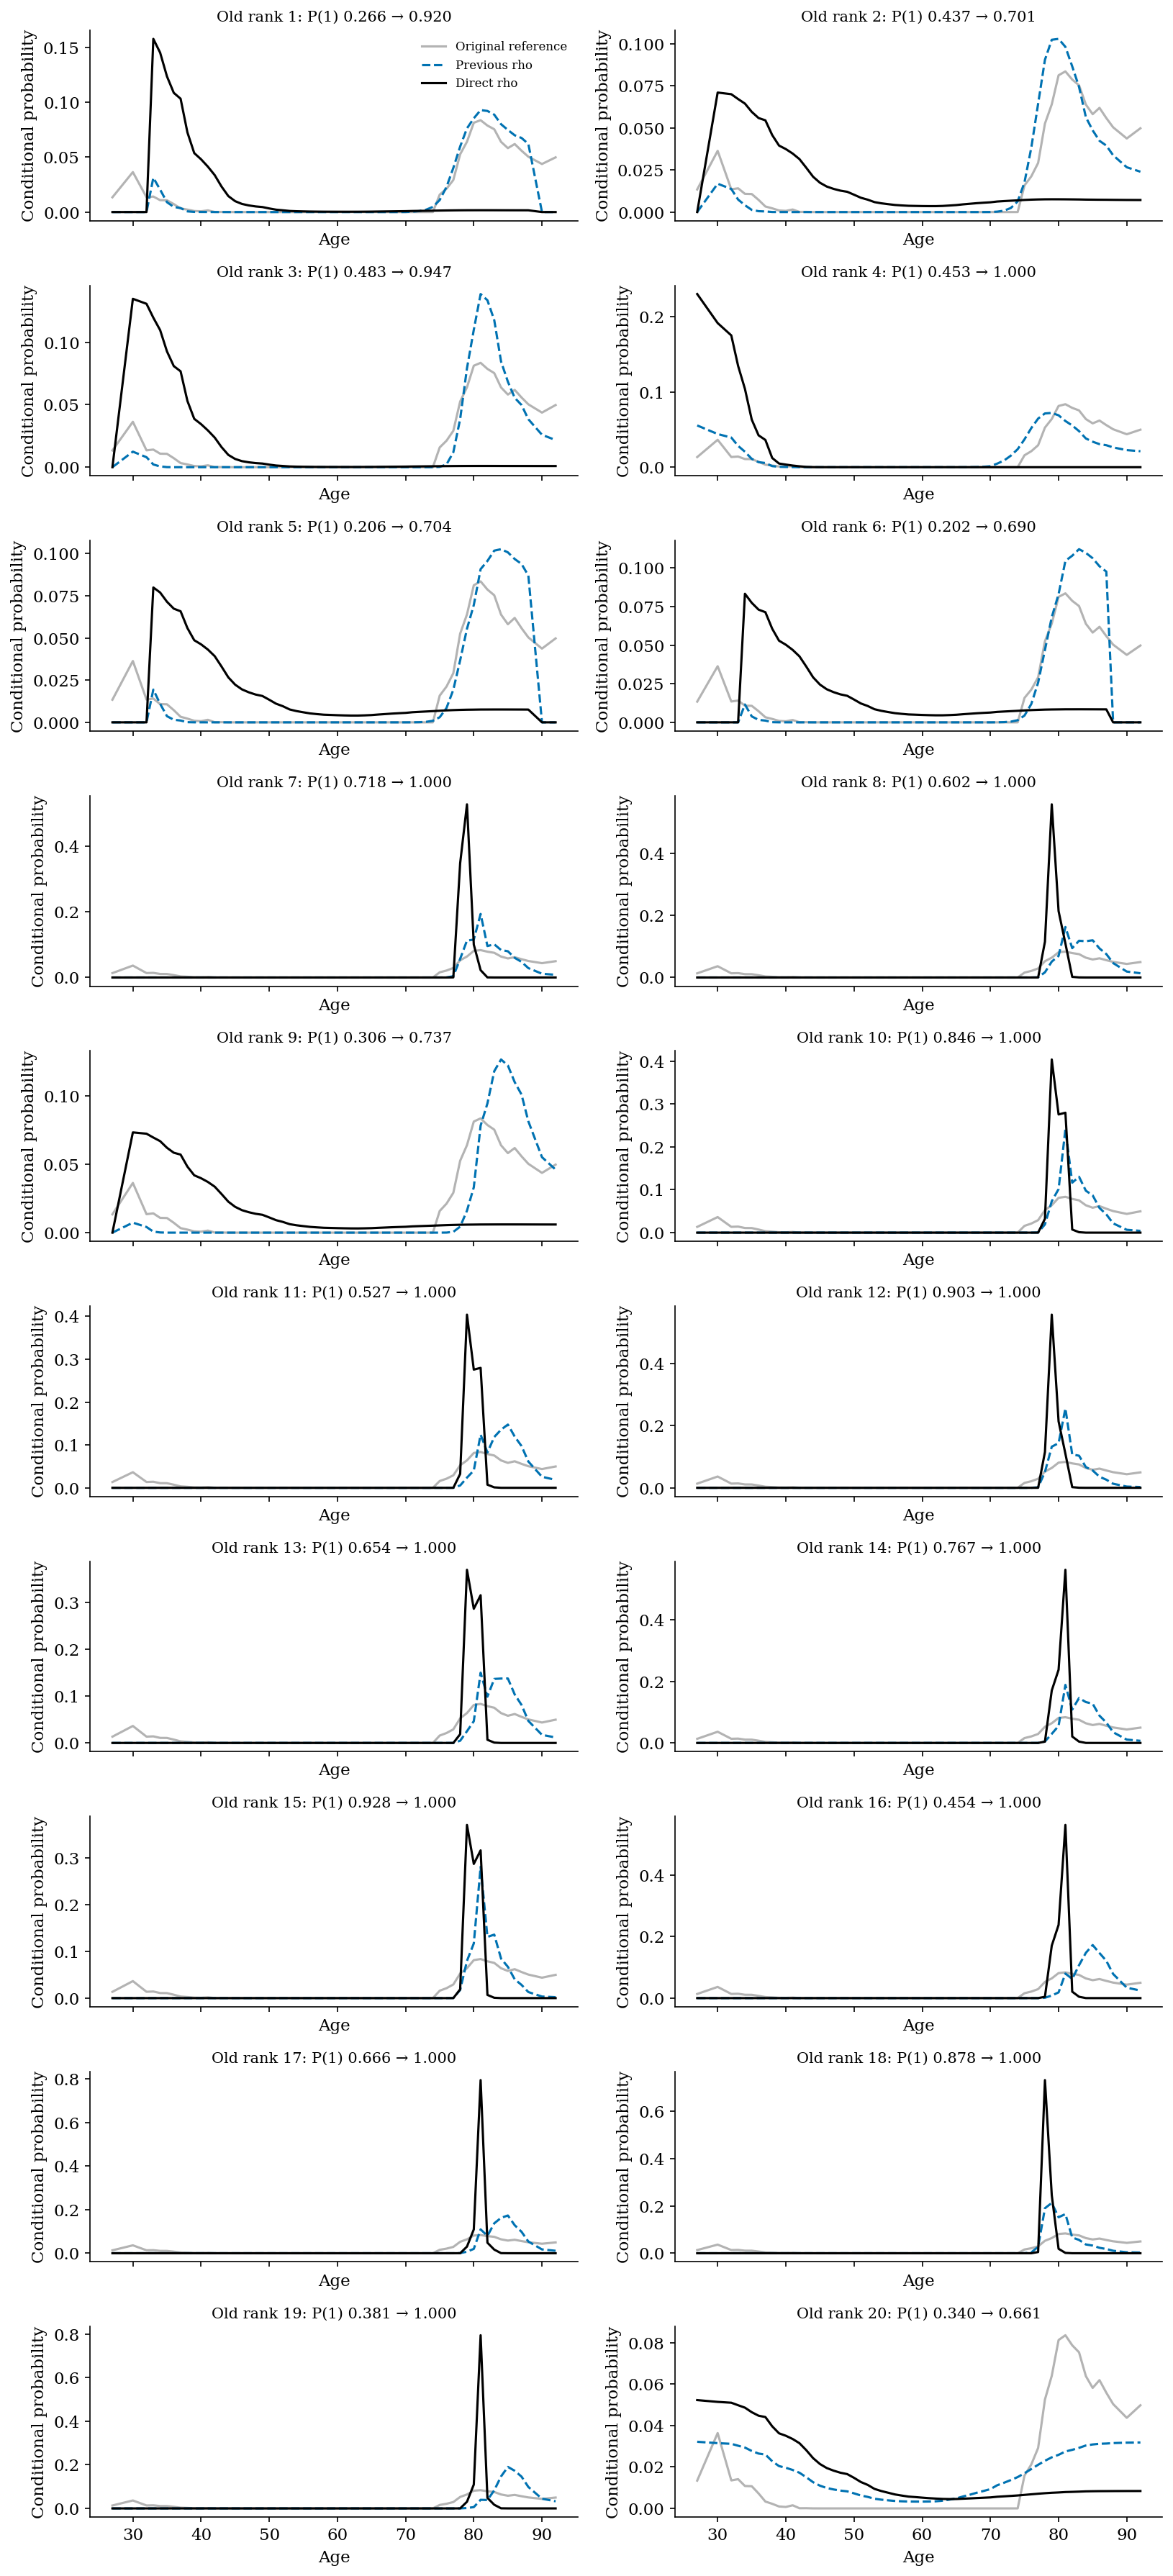

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
reference=reference_distribution();a=np.array(sorted(reference));ref=np.array([reference[x] for x in a])
def align(result):
    mapping=dict(zip(result['ages'],result['conditional']))
    return np.array([mapping.get(x,0.) for x in a])
print('Previous top20 before/after: identical coefficient fits; only rho fitting changes')
fig,axes=plt.subplots(10,2,figsize=(11,24),sharex=True)
old_table=pd.read_csv(TOP)
for ax,row in zip(axes.flat,comparison.itertuples()):
    old_row=old_table[old_table['rank']==row.old_rank].iloc[0]
    old=pickle.load(open(old_row.check_checkpoint,'rb'))
    # Older checkpoints omit ages: use the actual original fit setting/grid.
    new=pickle.load(open(row.checkpoint,'rb'))
    if 'ages' not in old:old=dict(old,ages=new['ages'])
    ax.plot(a,ref,color='.7',label='Original reference')
    ax.plot(a,align(old),color='#0072B2',ls='--',label='Previous rho')
    ax.plot(a,align(new),color='black',label='Direct rho')
    ax.set_title(f'Old rank {int(row.old_rank)}: P(1) {row.old_P1:.3f} → {row.P_1:.3f}',fontsize=10)
    ax.set(xlabel='Age',ylabel='Conditional probability')
axes.flat[0].legend(fontsize=8,frameon=False);fig.tight_layout();plt.show()


### #1: l2_4.21696503429e-05_intercept1

Auxiliary: **l2:4.21696503429e-05**; posterior: **l2:4.21696503429e-05**. Intercept: True; Delta=2. Relative moment residual=0.9267; correlation=-0.3985; boundary=False; optimizer success=True.

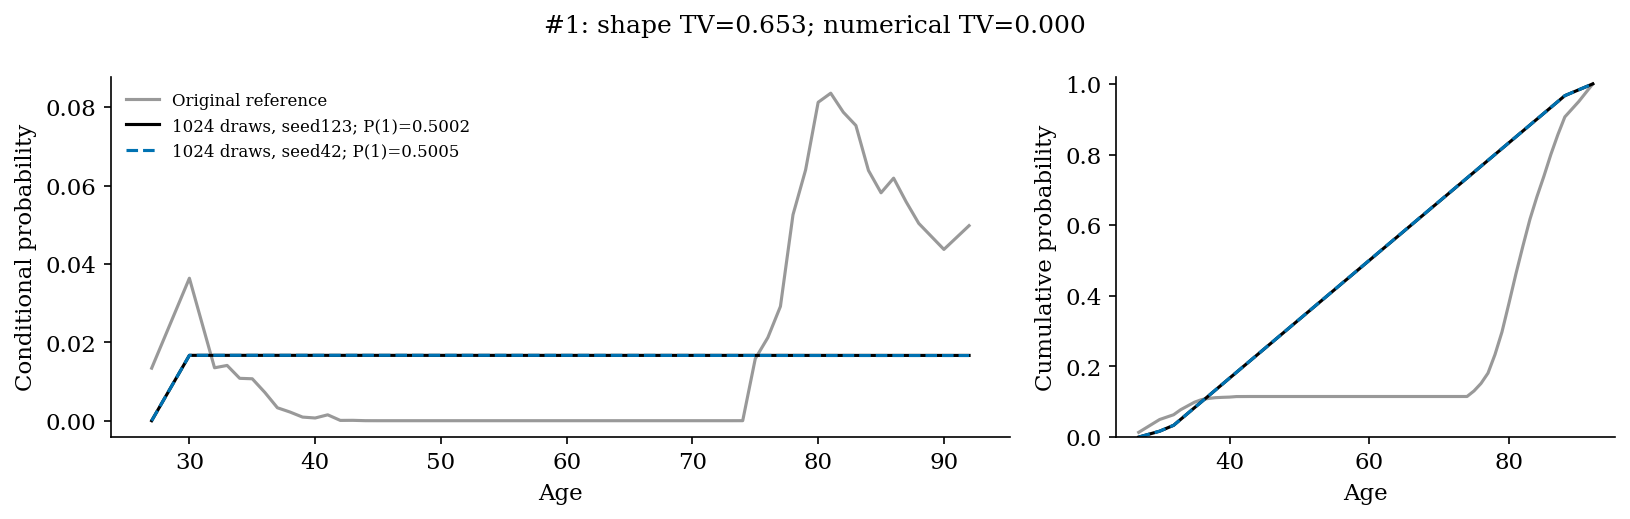

### #2: l2_0.0001_intercept1

Auxiliary: **l2:0.0001**; posterior: **l2:0.0001**. Intercept: True; Delta=2. Relative moment residual=3.867; correlation=-0.3853; boundary=False; optimizer success=True.

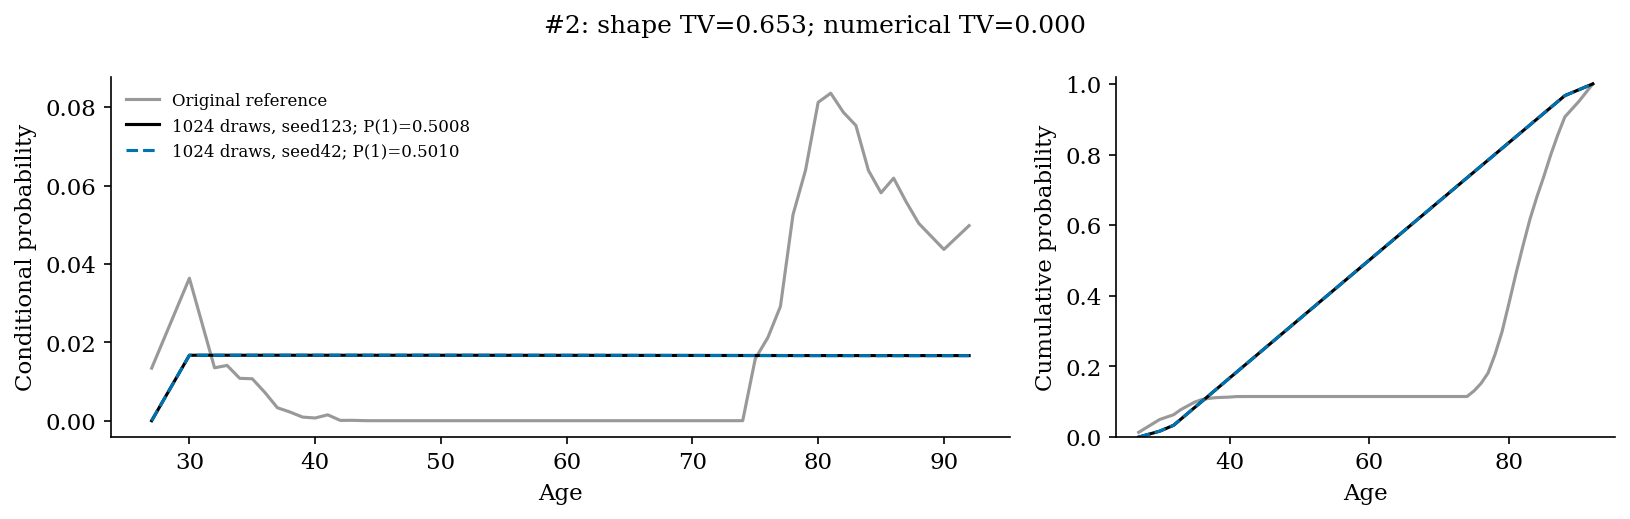

### #3: l2_4.21696503429e-05_intercept0

Auxiliary: **l2:4.21696503429e-05**; posterior: **l2:4.21696503429e-05**. Intercept: False; Delta=2. Relative moment residual=0.7657; correlation=-0.9934; boundary=True; optimizer success=True.

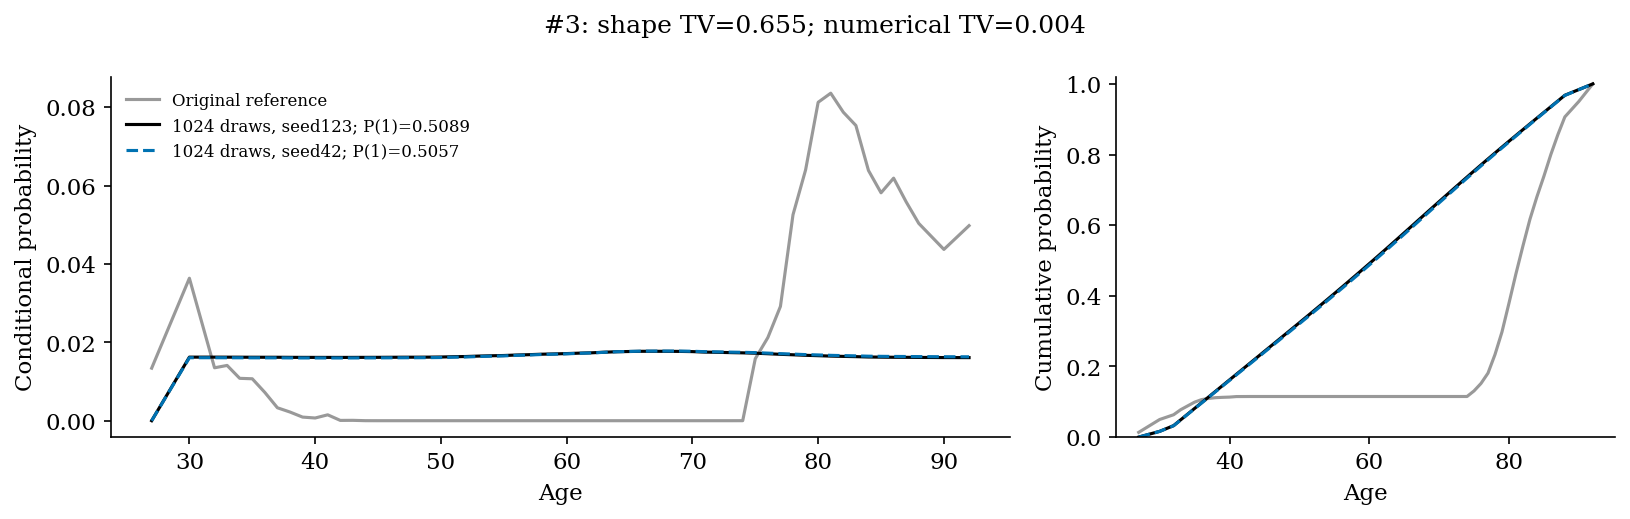

### #4: l2_0.0001_intercept0

Auxiliary: **l2:0.0001**; posterior: **l2:0.0001**. Intercept: False; Delta=2. Relative moment residual=3.107; correlation=-0.9944; boundary=True; optimizer success=True.

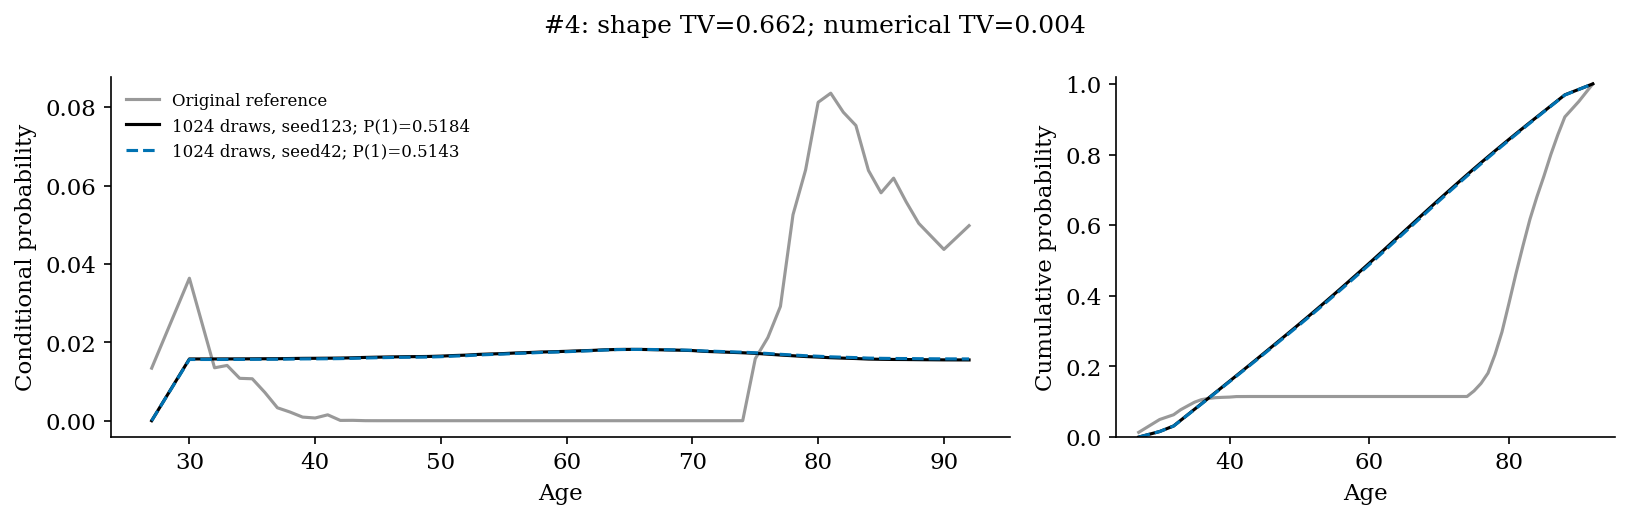

### #5: old_rank8

Auxiliary: **Logistic L1 0.0001 (full solve)**; posterior: **Logistic L2 1.2e-06 (full solve)**. Intercept: True; Delta=1. Relative moment residual=0.02882; correlation=-0.9999; boundary=True; optimizer success=True.

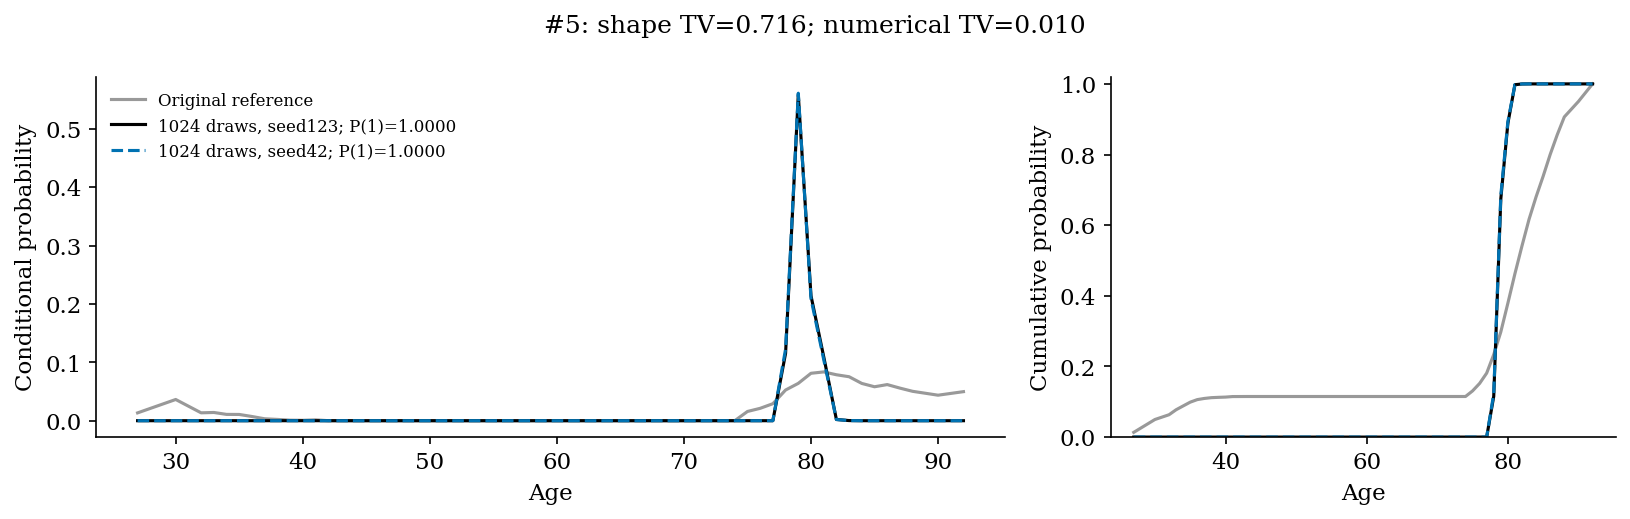

### #6: old_rank10

Auxiliary: **Logistic L1 0.0001 (full solve)**; posterior: **Logistic L2 1e-06 (full solve)**. Intercept: True; Delta=1. Relative moment residual=0.02882; correlation=-0.9999; boundary=True; optimizer success=True.

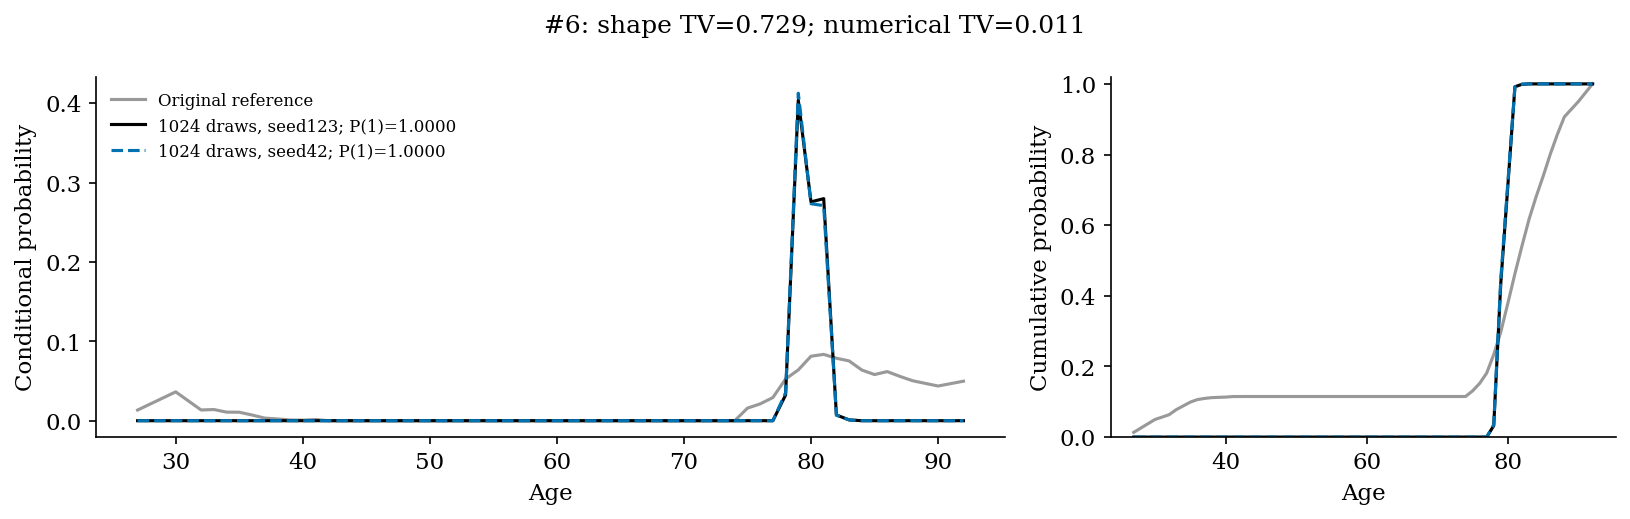

### #7: old_rank19

Auxiliary: **Logistic L1 0.0001 (full solve)**; posterior: **Logistic L2 6e-07 (full solve)**. Intercept: True; Delta=1. Relative moment residual=0.02882; correlation=-0.9999; boundary=True; optimizer success=True.

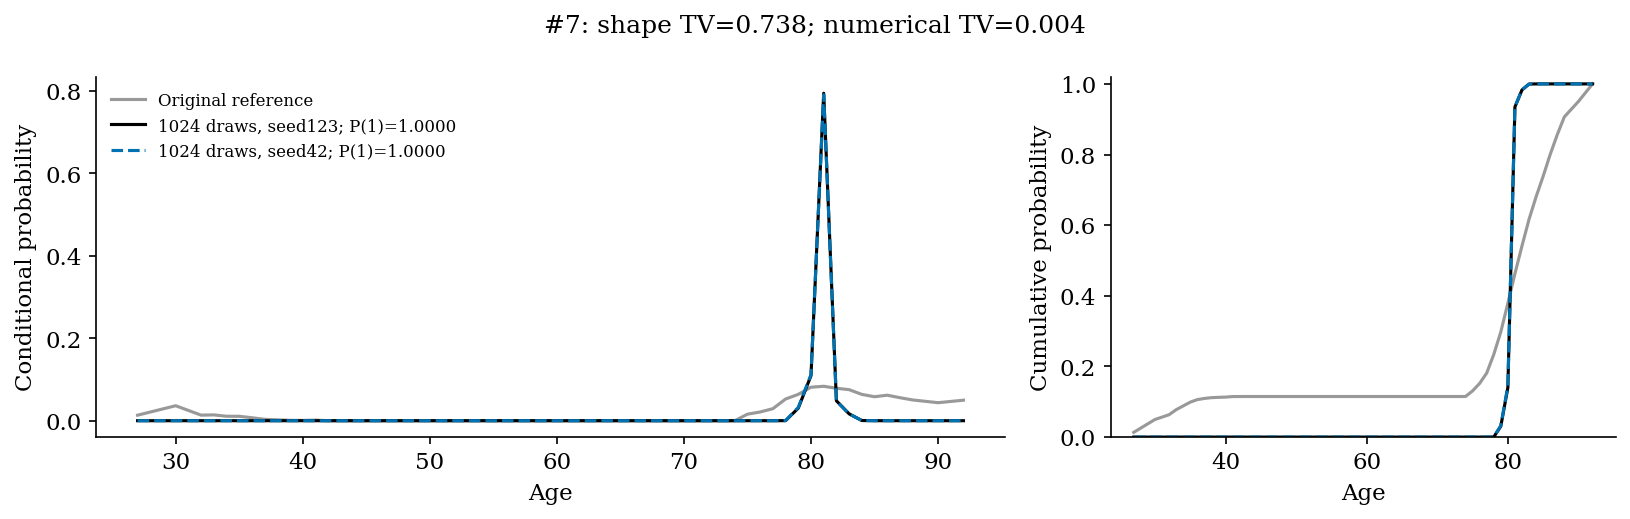

### #8: old_rank14

Auxiliary: **Logistic L1 0.0001 (full solve)**; posterior: **Logistic L2 8e-07 (full solve)**. Intercept: True; Delta=1. Relative moment residual=0.02882; correlation=-0.9999; boundary=True; optimizer success=True.

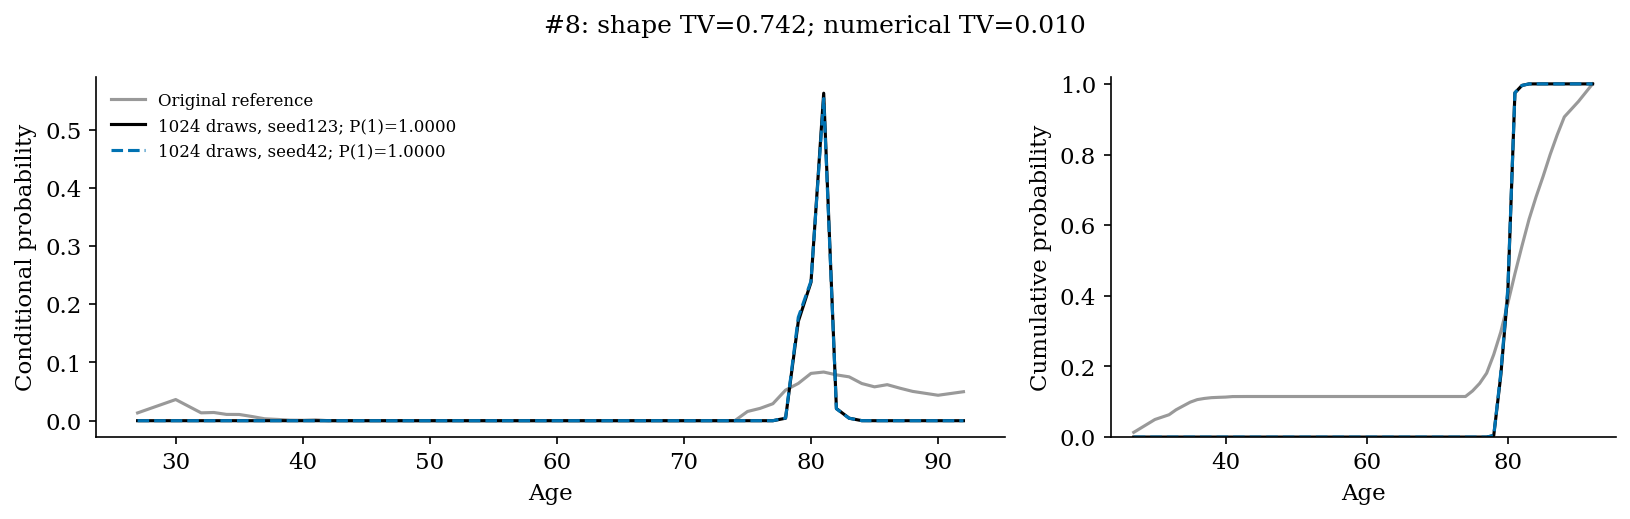

### #9: old_rank13

Auxiliary: **Logistic L1 0.0001 (full solve)**; posterior: **Logistic L1 1e-05 (full solve)**. Intercept: True; Delta=1. Relative moment residual=0.02882; correlation=-0.9999; boundary=True; optimizer success=True.

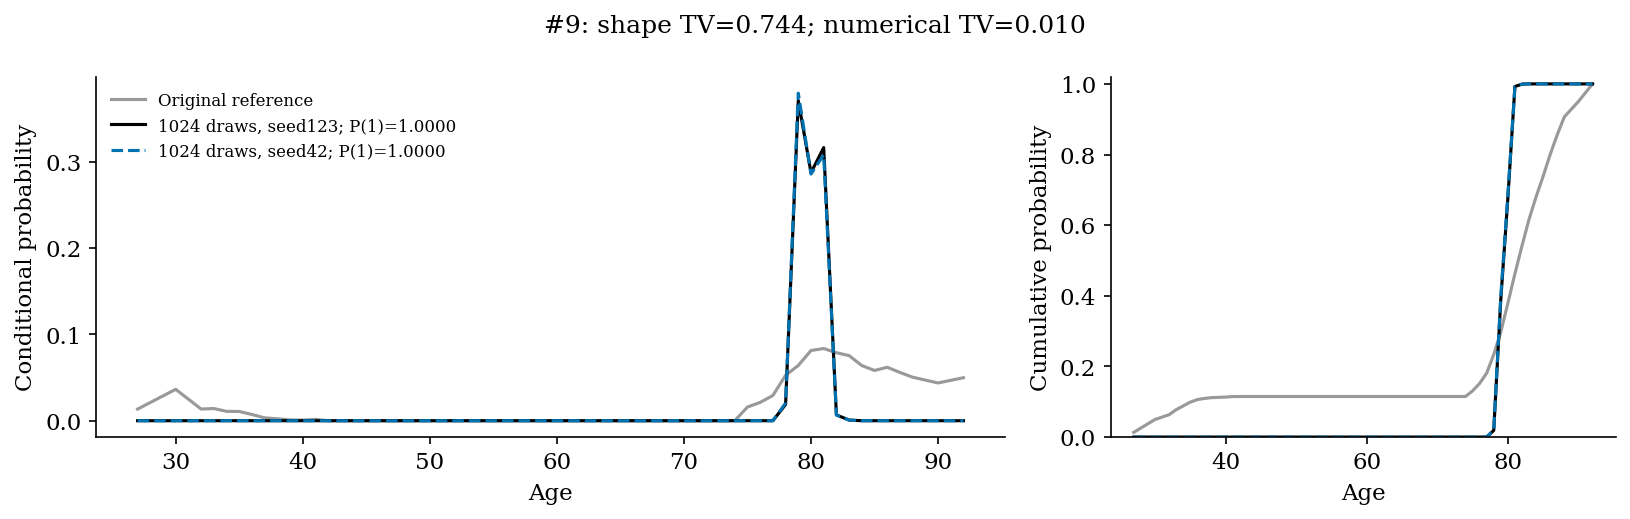

### #10: old_rank20

Auxiliary: **LS**; posterior: **Logistic L2 3.16227766017e-06 (full solve)**. Intercept: False; Delta=1. Relative moment residual=0.2251; correlation=-0.9994; boundary=True; optimizer success=True.

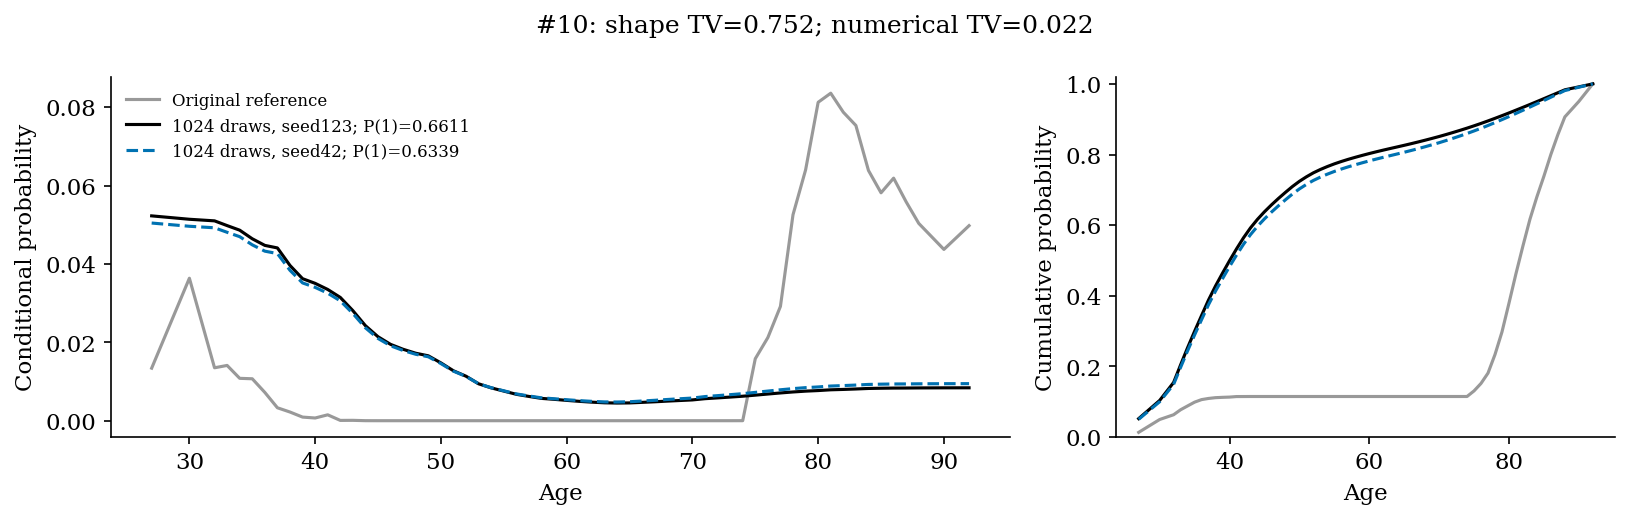

### #11: old_rank2

Auxiliary: **LS**; posterior: **Logistic FISTA 12 iterations**. Intercept: False; Delta=2. Relative moment residual=0.2234; correlation=-0.9994; boundary=True; optimizer success=True.

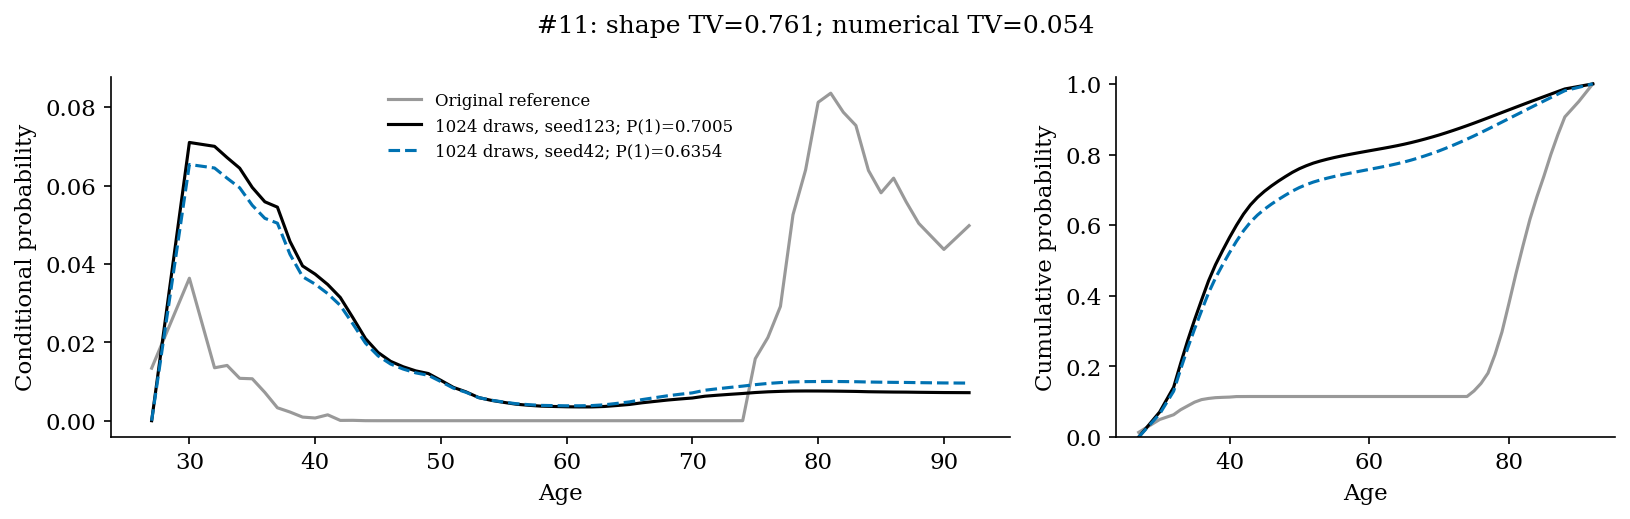

### #12: old_rank7

Auxiliary: **Logistic L1 0.0001 (full solve)**; posterior: **Logistic L2 1.5e-06 (full solve)**. Intercept: True; Delta=1. Relative moment residual=0.02882; correlation=-0.9999; boundary=True; optimizer success=True.

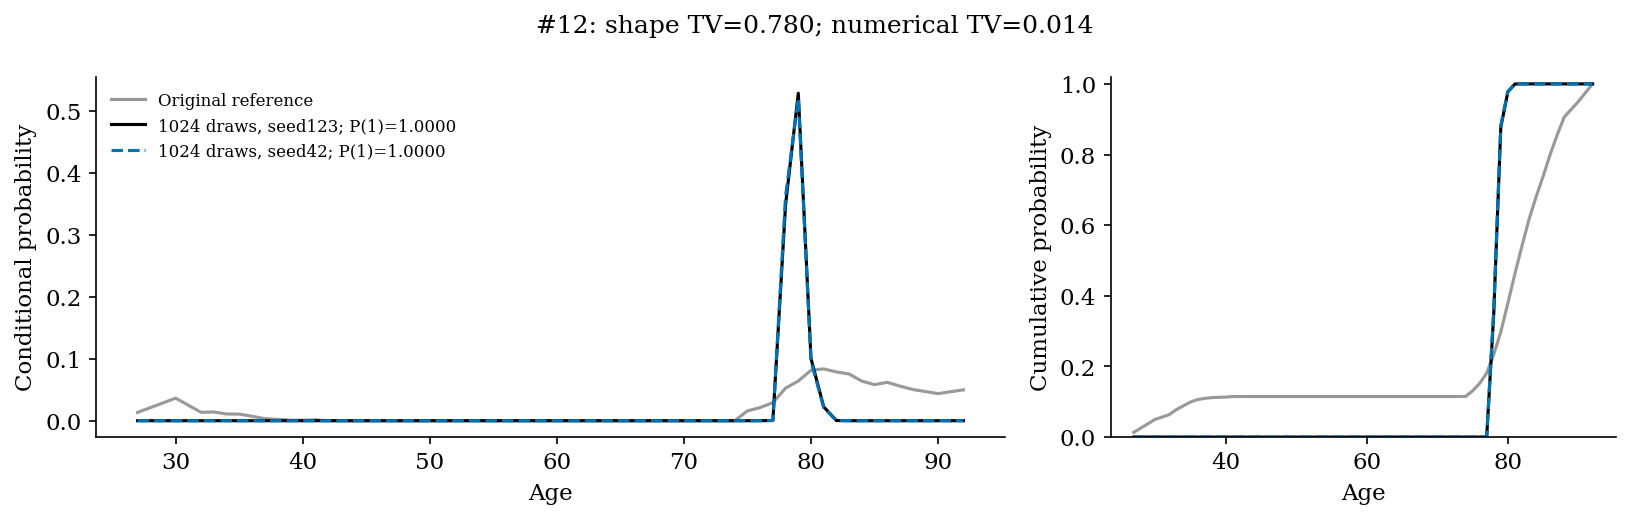

### #13: old_rank9

Auxiliary: **LS**; posterior: **Logistic L-BFGS 5 iterations**. Intercept: False; Delta=2. Relative moment residual=0.2234; correlation=-0.9994; boundary=True; optimizer success=True.

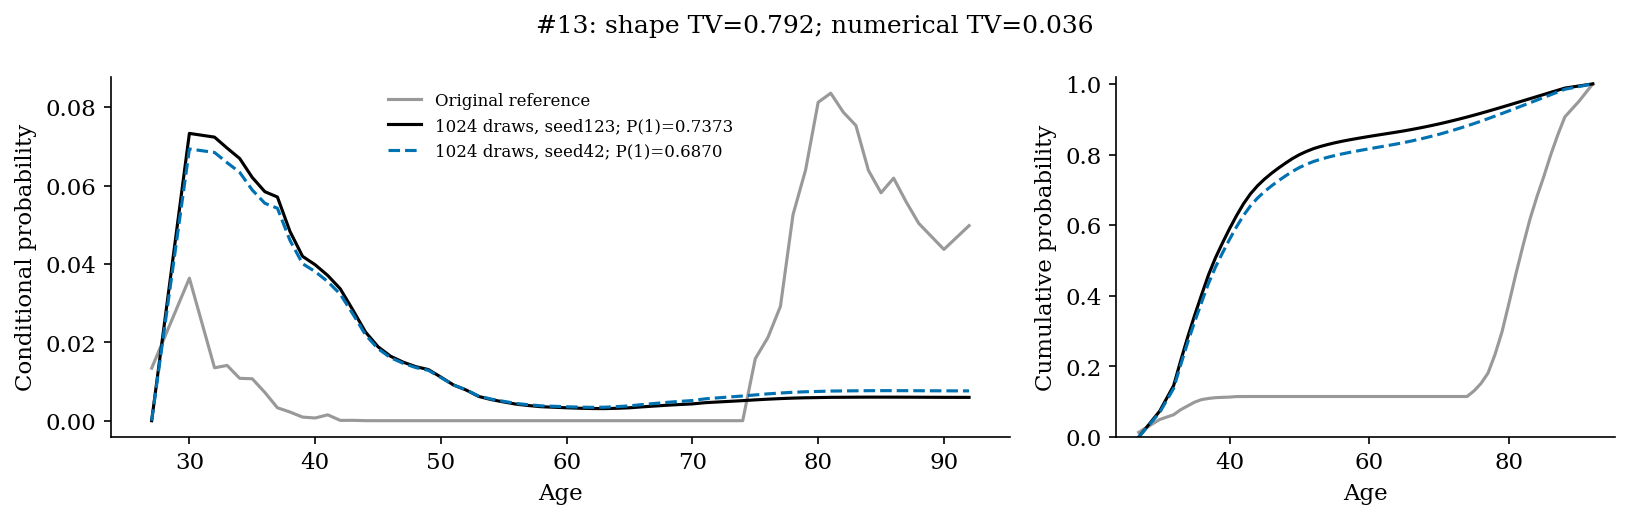

### #14: old_rank5

Auxiliary: **LS**; posterior: **Logistic L-BFGS 5 iterations**. Intercept: False; Delta=5. Relative moment residual=0.2211; correlation=-0.9994; boundary=True; optimizer success=True.

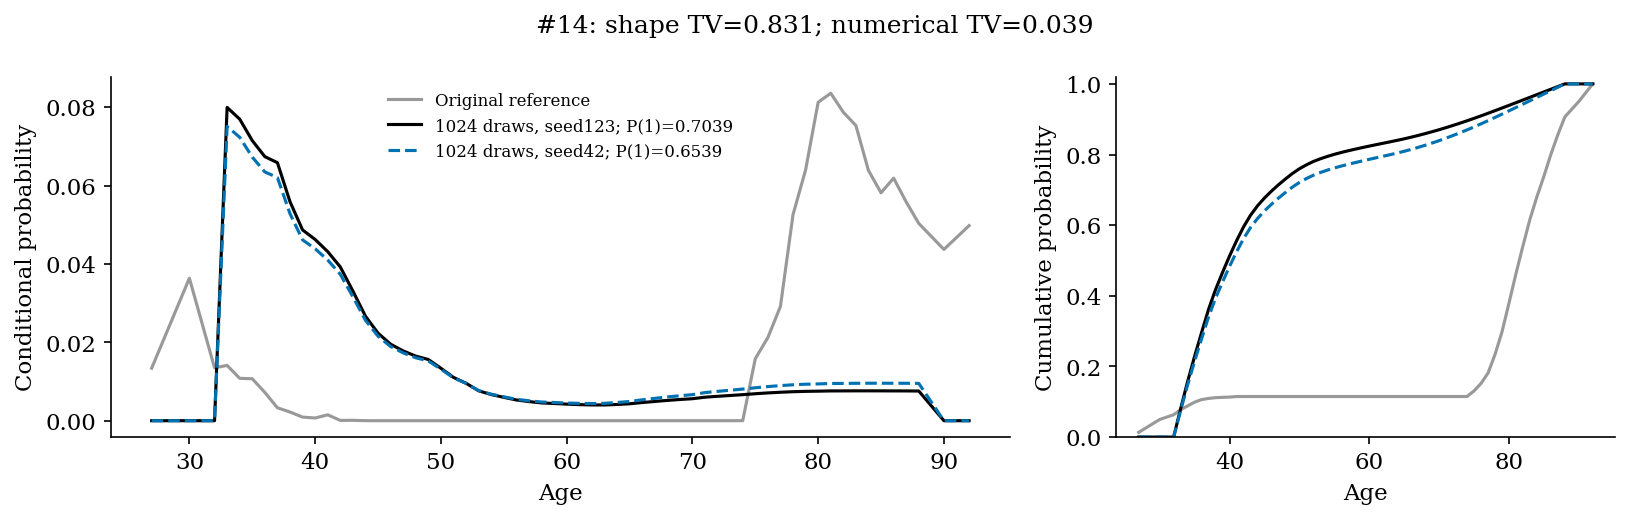

### #15: old_rank6

Auxiliary: **LS**; posterior: **Logistic L-BFGS 5 iterations**. Intercept: False; Delta=10. Relative moment residual=0.22; correlation=-0.9994; boundary=True; optimizer success=True.

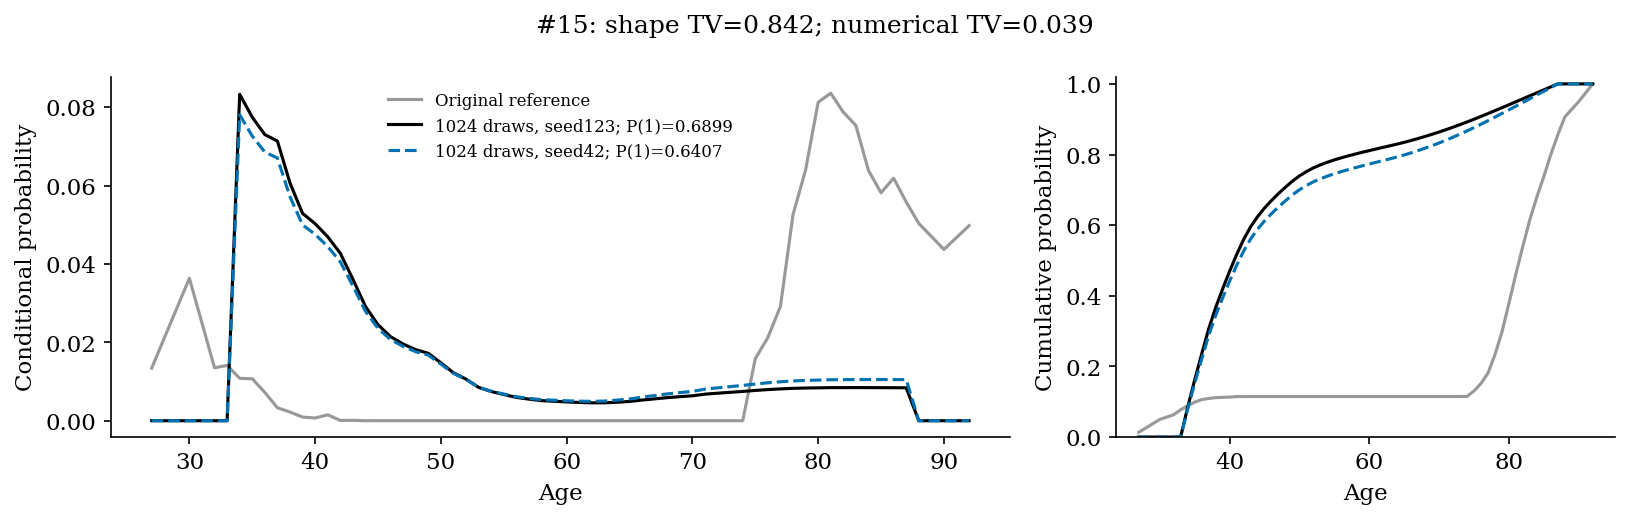

### #16: old_rank18

Auxiliary: **Logistic L1 0.0001 (full solve)**; posterior: **Logistic L2 2e-06 (full solve)**. Intercept: True; Delta=1. Relative moment residual=0.02882; correlation=-0.9999; boundary=True; optimizer success=True.

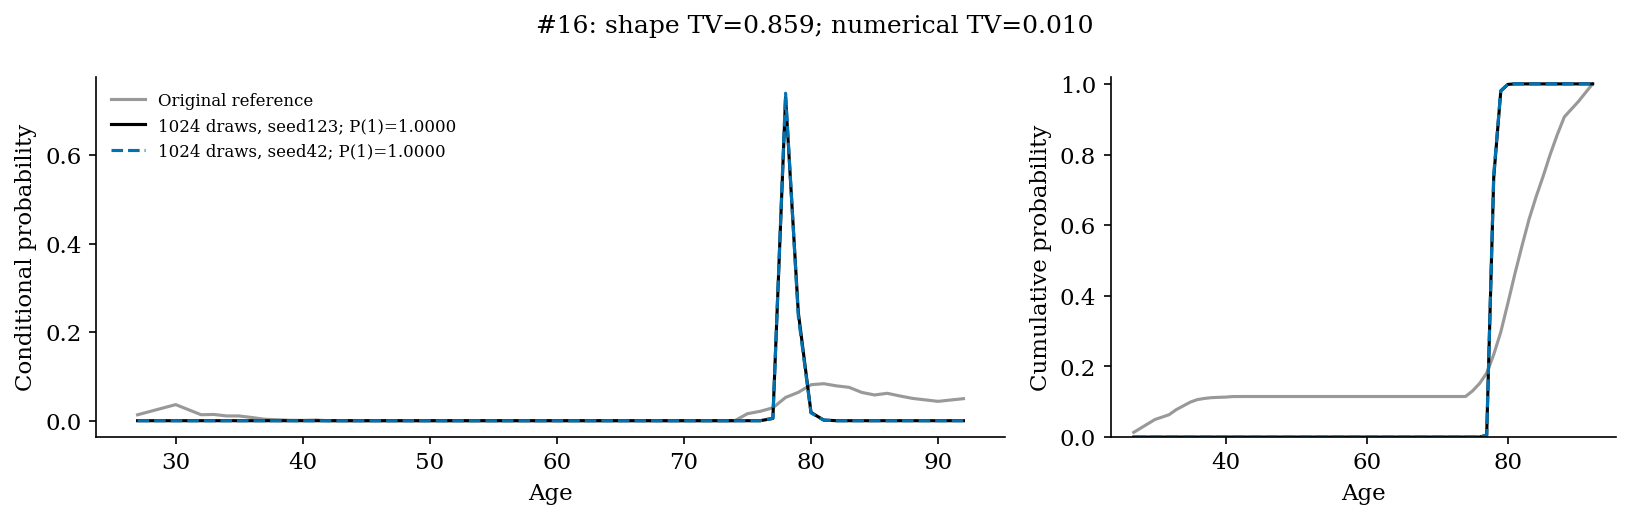

### #17: old_rank3

Auxiliary: **LS**; posterior: **Logistic FISTA 16 iterations**. Intercept: False; Delta=2. Relative moment residual=0.2234; correlation=-0.9994; boundary=True; optimizer success=True.

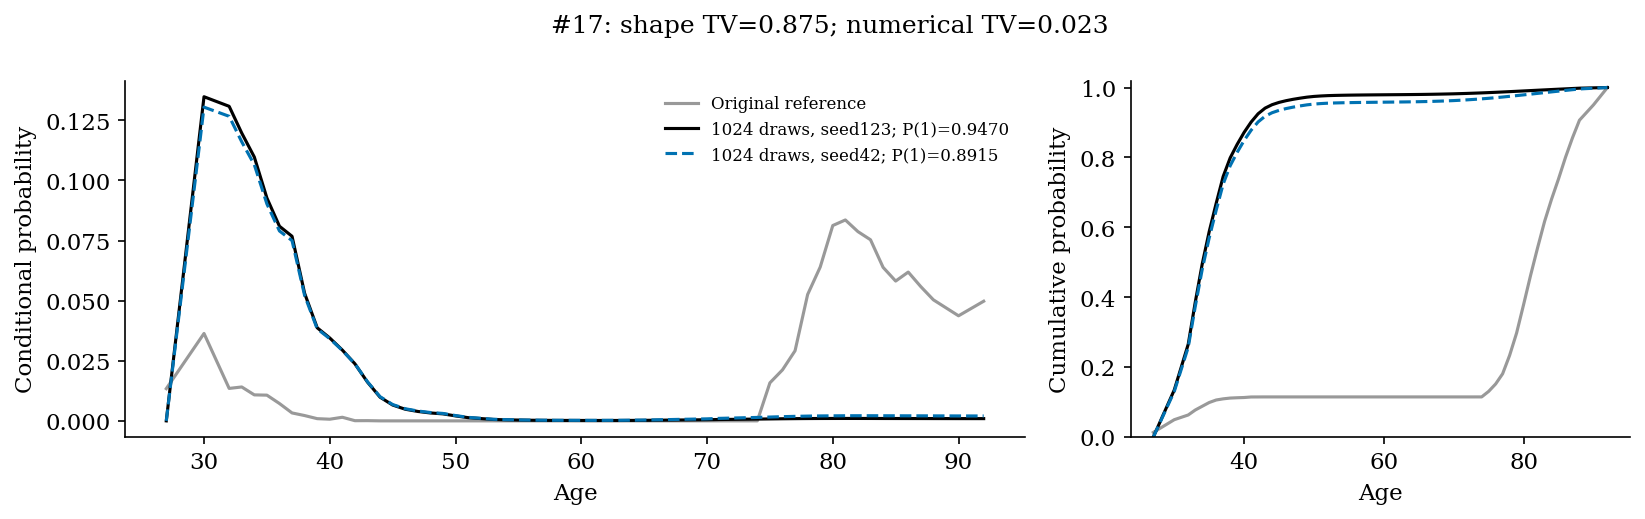

### #18: old_rank4

Auxiliary: **LS**; posterior: **Logistic L1 0.0001 (full solve)**. Intercept: False; Delta=1. Relative moment residual=0.2251; correlation=-0.9994; boundary=True; optimizer success=True.

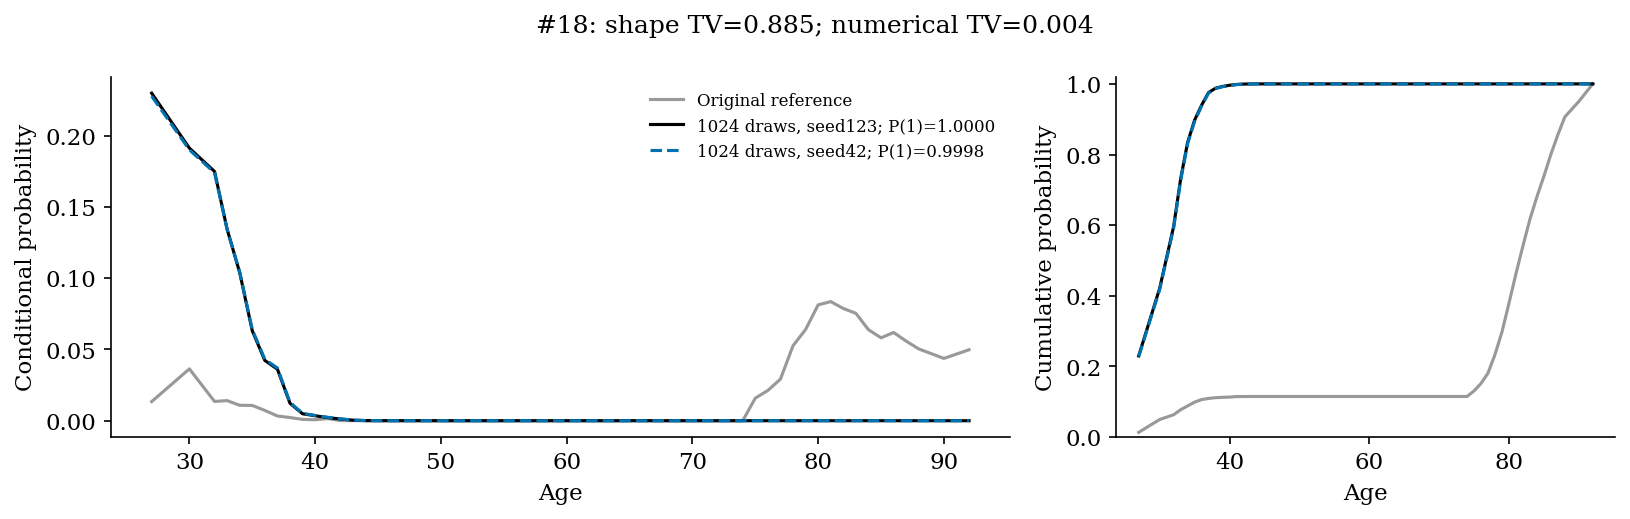

### #19: old_rank1

Auxiliary: **LS**; posterior: **Logistic FISTA 16 iterations**. Intercept: False; Delta=5. Relative moment residual=0.2211; correlation=-0.9994; boundary=True; optimizer success=True.

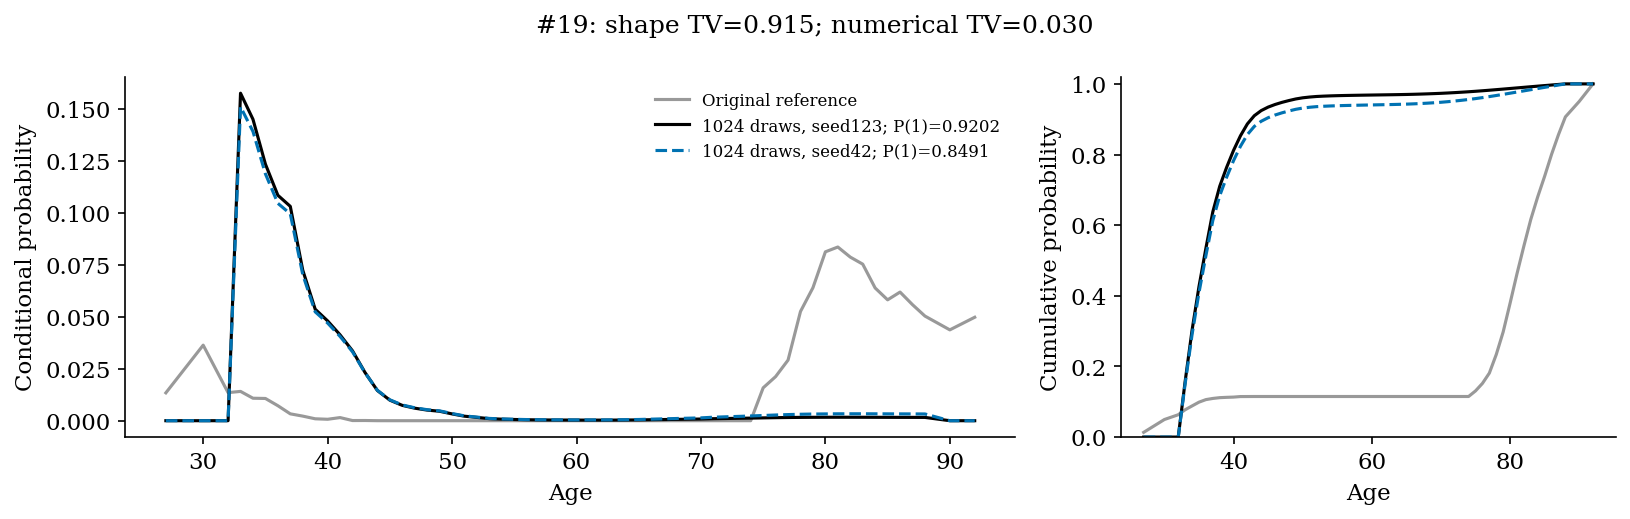

### #20: l2_1e-08_intercept0

Auxiliary: **l2:1e-08**; posterior: **l2:1e-08**. Intercept: False; Delta=2. Relative moment residual=0.7557; correlation=0.9999; boundary=True; optimizer success=True.

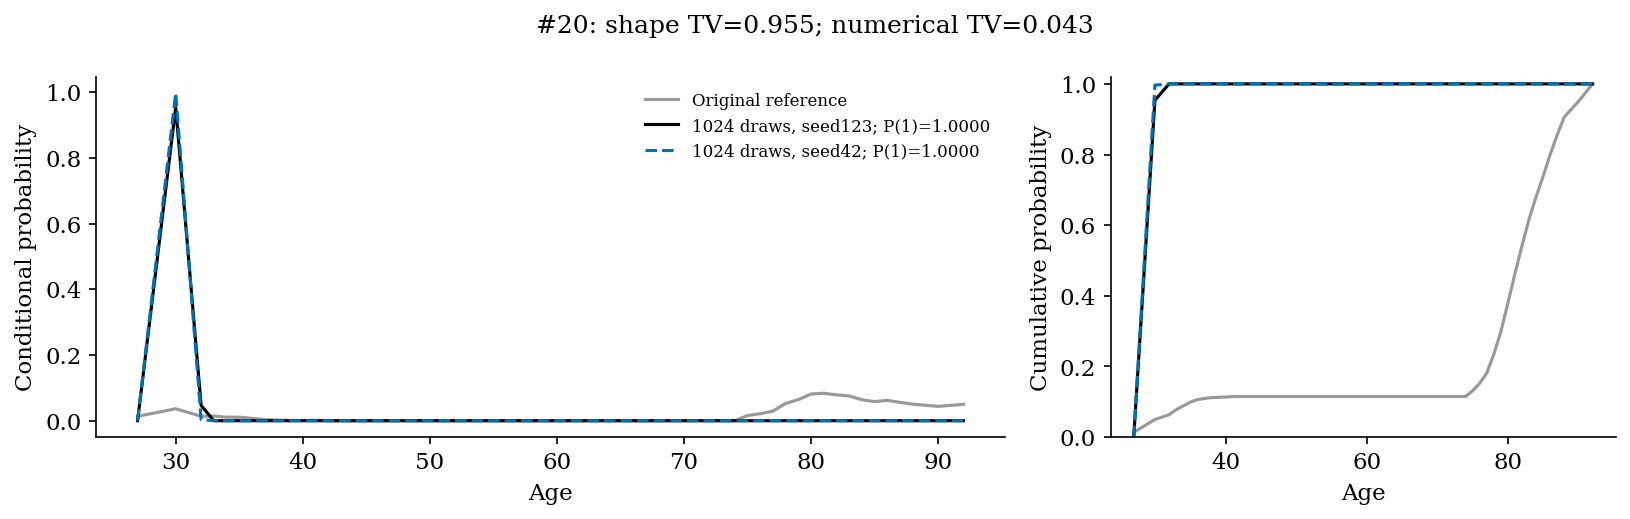

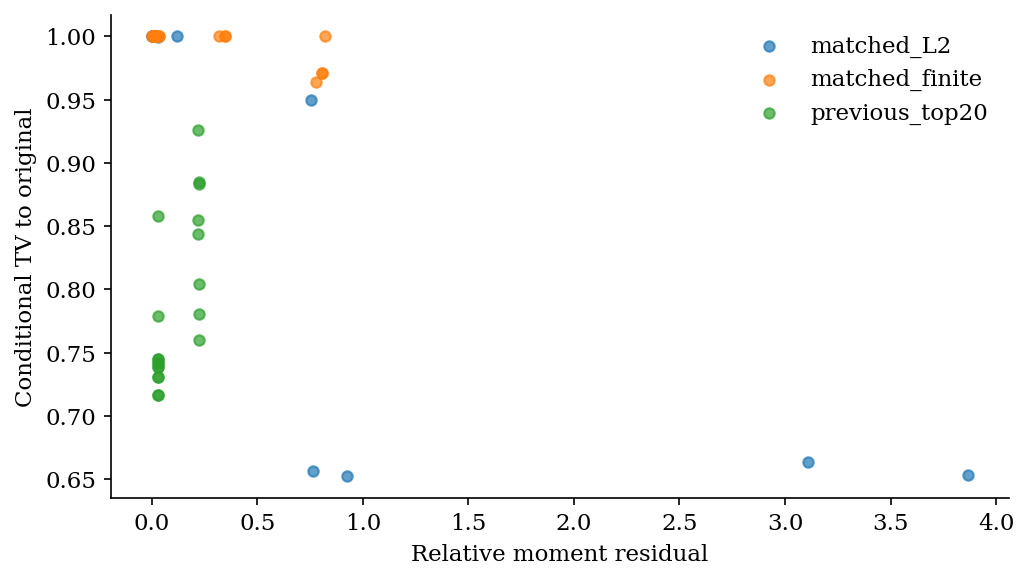

In [5]:
for row in best.itertuples():
    display(Markdown(f"### #{row.rank}: {row.id}\n\nAuxiliary: **{row.auxiliary}**; posterior: **{row.posterior}**. "
        f"Intercept: {row.intercept}; Delta={row.Delta}. Relative moment residual={row.relative_residual:.4g}; "
        f"correlation={row.correlation:.4g}; boundary={row.boundary}; optimizer success={row.optimizer_success}."))
    first=pickle.load(open(row.checkpoint,'rb'));second=pickle.load(open(row.check_checkpoint,'rb'))
    fig,(ax,cdf)=plt.subplots(1,2,figsize=(11,3.5),gridspec_kw={'width_ratios':[1.8,1]})
    for values,color,ls,label in [(ref,'.6','-','Original reference'),
        (align(first),'black','-',f"1024 draws, seed123; P(1)={first['P_1']:.4f}"),
        (align(second),'#0072B2','--',f"1024 draws, seed42; P(1)={second['P_1']:.4f}")]:
        ax.plot(a,values,color=color,ls=ls,lw=1.5,label=label)
        cdf.plot(a,np.cumsum(values),color=color,ls=ls,lw=1.5)
    ax.set(xlabel='Age',ylabel='Conditional probability');cdf.set(xlabel='Age',ylabel='Cumulative probability',ylim=(0,1.02))
    ax.legend(frameon=False,fontsize=8)
    fig.suptitle(f'#{row.rank}: shape TV={row.mean_TV:.3f}; numerical TV={row.numerical_TV:.3f}',fontsize=12)
    fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(7,4))
for origin,g in summary.groupby('origin'):
    ax.scatter(g.relative_residual,g.TV,label=origin,alpha=.7,s=25)
ax.set(xlabel='Relative moment residual',ylabel='Conditional TV to original')
ax.legend(frameon=False);fig.tight_layout();plt.show()
